# Operating System Random Number Generation

## Objective

To evaluate operating-system random-number generation mechanisms and investigate their suitability for cryptographic applications.

Three mechanisms are studied:

1. Linux /dev/urandom
2. OpenSSL rand
3. Windows CNG / .NET Cryptographic RNG

## 1. Random Data Generation

At least 1 MB of random data was generated using each mechanism.

- Linux: /dev/urandom
- OpenSSL: openssl rand
- Windows: .NET RandomNumberGenerator API

Each generated file contains 1,048,576 bytes.

## 2. Byte Frequency Distribution

Byte frequency analysis checks how frequently each possible byte value (0–255) occurs.

For uniformly distributed random bytes, each value is expected to occur approximately the same number of times.

A chi-square test is used to compare observed and expected frequencies.

## 3. Bit Distribution

Random data should have approximately equal numbers of zeros and ones.

The bit balance test checks the proportion of 0s and 1s.

Expected distribution:

- Zeros: approximately 50%
- Ones: approximately 50%

## 4. Repeated Pattern Analysis

Repeated patterns are checked using:

- Consecutive identical bytes
- Repeated 4-byte blocks

Random data can contain occasional repetitions. Their presence alone does not indicate a weak generator.

## 5. Serial Correlation

Serial correlation measures the relationship between consecutive bytes.

A value close to zero indicates little linear correlation between neighboring bytes.

Pearson correlation is used for this analysis.

## 6. Statistical Tests

The following tests are applied:

1. Chi-square test: Checks byte-frequency uniformity.
2. Bit balance test: Checks equal distribution of zeros and ones.
3. Runs test: Checks the sequence of consecutive bits.
4. Serial correlation test: Checks relationships between adjacent bytes.

A p-value below 0.05 indicates a statistically significant deviation under the test's assumptions.


Analyzing: Linux /dev/urandom
File Size: 1048576 bytes
Byte Chi-square p-value: 0.40023572943580915
Bit Ones: 4193308
Bit Zeros: 4195300
Bit Balance p-value: 0.49181396552251405
Repeated Adjacent Bytes: 4143
Repeated 4-byte Blocks: 9
Serial Correlation: 0.0003814945614477407
Runs Test p-value: 0.9223066053492321

Analyzing: OpenSSL rand
File Size: 1048576 bytes
Byte Chi-square p-value: 0.10172264336836781
Bit Ones: 4194461
Bit Zeros: 4194147
Bit Balance p-value: 0.9139413038822076
Repeated Adjacent Bytes: 4038
Repeated 4-byte Blocks: 10
Serial Correlation: -0.0007367124095715859
Runs Test p-value: 0.8754377200286858

Analyzing: Windows CNG
File Size: 1048576 bytes
Byte Chi-square p-value: 0.25834902594230524
Bit Ones: 4195461
Bit Zeros: 4193147
Bit Balance p-value: 0.42452092086774895
Repeated Adjacent Bytes: 4020
Repeated 4-byte Blocks: 9
Serial Correlation: 0.00077510119372384
Runs Test p-value: 0.8845272730676983

========== FINAL COMPARISON ==========
         Generator  Size (byt

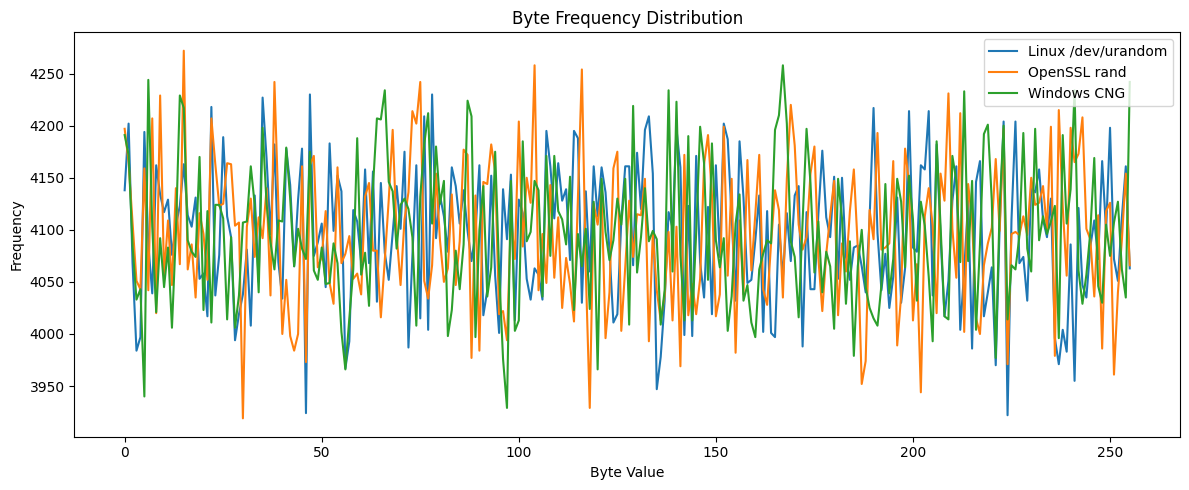


All analysis results saved successfully.


In [1]:
%run analyze_rng.py

## 7. Linux Random Number Generation

Linux uses a kernel-based Cryptographically Secure Pseudorandom Number Generator (CSPRNG).

- It collects entropy from device drivers and environmental sources.
- The collected entropy initializes the kernel random generator.
- /dev/urandom provides random bytes from the kernel CSPRNG.
- It is suitable for cryptographic applications after initialization.

Linux manages its random state inside the kernel and provides random data to user applications.

## 8. OpenSSL Random Number Generation

OpenSSL uses a Cryptographically Secure Pseudorandom Number Generator (CSPRNG).

- The openssl rand command generates random bytes.
- It uses the RAND_bytes function.
- It uses a DRBG-based random generation mechanism.
- It obtains seed material from trusted operating-system sources.
- It automatically initializes and reseeds its generator.

OpenSSL is suitable for cryptographic random-number generation when its trusted entropy source is available.

## 9. Windows Random Number Generation

Windows provides Cryptography API: Next Generation (CNG).

- CNG provides cryptographic services.
- BCryptGenRandom generates random bytes.
- The .NET RandomNumberGenerator API provides access to cryptographic random data.
- The operating system manages the random generator and its internal state.

It is suitable for generating cryptographic keys, tokens and other security-related random values.

## 10. Comparison of Random Number Generators

| Feature | Linux | OpenSSL | Windows |
|---|---|---|---|
| Mechanism | /dev/urandom | openssl rand | .NET CNG-backed API |
| Type | Kernel CSPRNG | DRBG-based CSPRNG | OS cryptographic RNG |
| Entropy source | OS entropy sources | Trusted OS entropy | Windows system entropy |
| Cryptographic use | Yes | Yes | Yes |

All three mechanisms are designed for cryptographic random-number generation.

## 11. Limitations of Statistical Tests

Passing statistical tests does not guarantee cryptographic security.

Reasons:

1. Statistical tests only examine observable properties of output.
2. They cannot prove that future output is unpredictable.
3. They cannot detect every possible weakness in an algorithm.
4. A predictable seed may produce statistically random-looking output.
5. A weak generator may pass several statistical tests.

Cryptographic security requires unpredictability, secure seed management and resistance to attacks, not just statistical randomness.

## 12. Conclusion

In this experiment, 1 MB of random data was generated using Linux /dev/urandom, OpenSSL rand and Windows CNG-backed .NET API.

The generated data was analyzed using byte-frequency, bit-distribution, repeated-pattern, chi-square, runs and serial-correlation tests.

The experiment demonstrates that statistical testing helps identify certain patterns and biases, but cannot independently prove cryptographic security.

Operating-system CSPRNGs and trusted cryptographic libraries should be preferred for security-related applications.


Analyzing: Linux /dev/urandom
File Size: 1048576 bytes
Byte Chi-square p-value: 0.40023572943580915
Bit Ones: 4193308
Bit Zeros: 4195300
Bit Balance p-value: 0.49181396552251405
Repeated Adjacent Bytes: 4143
Repeated 4-byte Blocks: 9
Serial Correlation: 0.0003814945614477407
Runs Test p-value: 0.9223066053492321

Analyzing: OpenSSL rand
File Size: 1048576 bytes
Byte Chi-square p-value: 0.10172264336836781
Bit Ones: 4194461
Bit Zeros: 4194147
Bit Balance p-value: 0.9139413038822076
Repeated Adjacent Bytes: 4038
Repeated 4-byte Blocks: 10
Serial Correlation: -0.0007367124095715859
Runs Test p-value: 0.8754377200286858

Analyzing: Windows CNG
File Size: 1048576 bytes
Byte Chi-square p-value: 0.25834902594230524
Bit Ones: 4195461
Bit Zeros: 4193147
Bit Balance p-value: 0.42452092086774895
Repeated Adjacent Bytes: 4020
Repeated 4-byte Blocks: 9
Serial Correlation: 0.00077510119372384
Runs Test p-value: 0.8845272730676983

========== FINAL COMPARISON ==========
         Generator  Size (byt

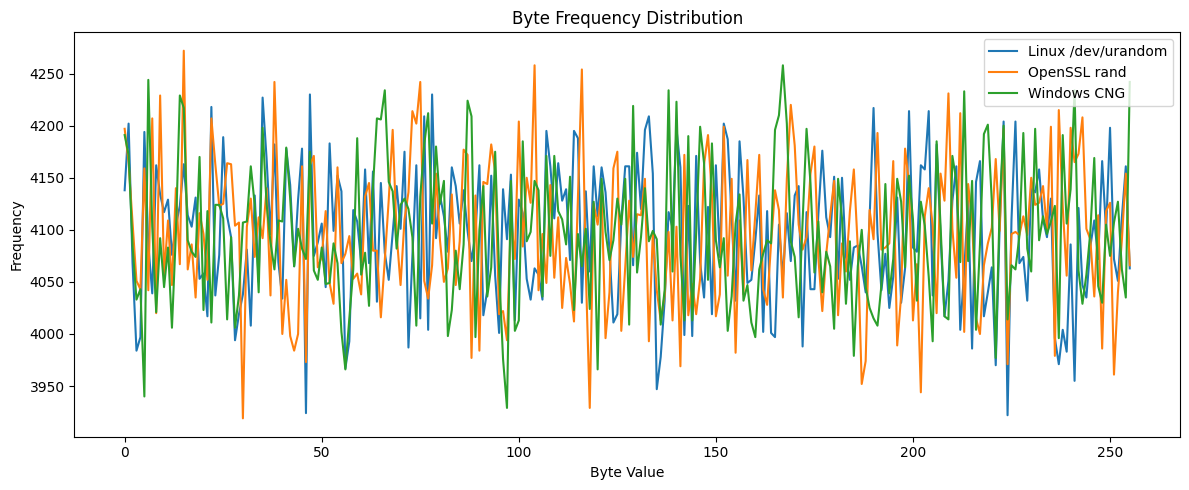


All analysis results saved successfully.


In [2]:
%run analyze_rng.py